# Pipeline de Préprocessing des Signaux Vibratoires Industriels

## Contexte et Objectifs

L'objectif de ce notebook est de construire un **dataset propre et exploitable pour la prédiction des gaps / valeurs manquantes dans des signaux vibratoires industriels**.

### Principes et Contraintes :
1. **Pas d'entraînement de modèle** à cette étape.
2. **Conservation de la forme tabulaire** : aucune transformation en fenêtres, séquences, spectrogrammes ou feature engineering.
3. **Traitements appliqués** :
   - Ingestion et nettoyage des fichiers CSV (gestion des conflits Git et formats européens).
   - Traitement des `NaN` par **interpolation linéaire des petits gaps** (longueur <= SHORT_GAP_THRESHOLD).
   - **Tronquage des séries** à partir du premier long gap (longueur > SHORT_GAP_THRESHOLD).
   - **Réduction des données `OFF` à 10 %** (pression < 5.0 bar ou état `OFF`) via échantillonnage reproductible.
   - Fusion dans un dataset tabulaire unique : `preprocessed_data.csv`.



## 1. Imports & Configuration

Définition des paramètres globaux configurables, notamment le seuil de longueur des gaps (`SHORT_GAP_THRESHOLD`).



In [7]:
import glob
import io
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration des seuils (Facilement modulables)
SHORT_GAP_THRESHOLD = 10           # Seuil max pour interpolation linéaire (petits gaps)
PRESSURE_OPERATIONAL_THRESHOLD = 5.0  # Seuil de pression en bar (séparation OFF / ON)
OFF_KEEP_FRACTION = 0.10            # Conservation de 10% des données OFF
RANDOM_STATE = 42                   # Graine aléatoire fixe pour la reproductibilité

# Chemins des dossiers (compatibles execution depuis notebooks/ ou racine)
if os.path.exists('data/raw'):
    DATA_DIR = 'data/raw'
    OUTPUT_DIR = 'data/processed'
elif os.path.exists('../data/raw'):
    DATA_DIR = '../data/raw'
    OUTPUT_DIR = '../data/processed'
else:
    DATA_DIR = 'data/raw'
    OUTPUT_DIR = 'data/processed'

os.makedirs(OUTPUT_DIR, exist_ok=True)
FINAL_CSV_PATH = os.path.join(OUTPUT_DIR, 'preprocessed_data.csv')
ROOT_CSV_PATH = '../data/processed/preprocessed_data.csv'

print(f"SHORT_GAP_THRESHOLD: {SHORT_GAP_THRESHOLD}")
print(f"PRESSURE_OPERATIONAL_THRESHOLD: {PRESSURE_OPERATIONAL_THRESHOLD} bar")
print(f"OFF_KEEP_FRACTION: {OFF_KEEP_FRACTION * 100}%")
print(f"DATA_DIR: {DATA_DIR}")



SHORT_GAP_THRESHOLD: 10
PRESSURE_OPERATIONAL_THRESHOLD: 5.0 bar
OFF_KEEP_FRACTION: 10.0%
DATA_DIR: ../data/raw


## 2. Définition des Fonctions Modulaires

Conformément au cahier des charges, le code est organisé en fonctions distinctes et réutilisables.



In [ ]:
def parse_european_num(val):
    """
    Parse les valeurs numériques brutes (gestion des virgules européennes, 
    des points de milliers et des chaînes 'OFF' / 'NaN').
    """
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s.upper() in ['NAN', 'NONE', '', 'NULL', 'OFF']:
        return np.nan
    s = s.replace(',', '.')
    parts = s.split('.')
    if len(parts) > 2:
        s = ''.join(parts[:-1]) + '.' + parts[-1]
    try:
        return float(s)
    except:
        return np.nan

def load_csv_files(data_dir):
    """
    Parcourt le dossier data_dir, charge les CSV, résout les conflits Git 
    et normalise la structure des colonnes tout en conservant les noms et métadonnées.
    """
    csv_paths = sorted(glob.glob(os.path.join(data_dir, '*.csv')))
    dfs = []
    
    for path in csv_paths:
        with open(path, 'r', encoding='utf-8', errors='ignore') as fp:
            raw = fp.read()
        
        # Traitement des marqueurs de conflits Git
        if '<<<<<<< HEAD' in raw:
            head_end = raw.find('=======')
            raw = raw[len('<<<<<<< HEAD\n'):head_end].strip() + '\n'
            
        first_line = raw.splitlines()[0] if raw.splitlines() else ''
        sep = ';' if ';' in first_line else ','
        
        df_raw = pd.read_csv(io.StringIO(raw), sep=sep, dtype=str)
        filename = os.path.basename(path)
        pump_id = filename[0]  # 'A', 'B', or 'C'
        
        # Standardisation des préfixes de capteurs (A_ACR_Mot.PV -> ACR_Mot.PV)
        new_cols = {}
        for col in df_raw.columns:
            if col.startswith(f'{pump_id}_'):
                new_cols[col] = col[len(f'{pump_id}_'):]
            else:
                new_cols[col] = col
        df_raw = df_raw.rename(columns=new_cols)
        
        # Conversion numérique propre des colonnes de données
        for col in df_raw.columns:
            if col != 'Timestamp':
                df_raw[col] = df_raw[col].apply(parse_european_num)
                
        # Ajout de l'identifiant d'équipement juste après Timestamp
        df_raw.insert(1, 'equipment_id', pump_id)
        dfs.append((filename, df_raw))
        
    return dfs

def detect_gaps(series):
    """
    Détecte toutes les séquences consécutives de NaN (gaps) dans une série.
    """
    is_nan = series.isna()
    if not is_nan.any():
        return []
    
    blocks = (~is_nan).cumsum()[is_nan]
    gaps = []
    for block_id, group in series[is_nan].groupby(blocks):
        gaps.append({
            'start_idx': group.index[0],
            'end_idx': group.index[-1],
            'length': len(group)
        })
    return gaps

def classify_gaps(gaps, threshold):
    """
    Classe les gaps en petits gaps (<= threshold) et grands gaps (> threshold).
    """
    short_gaps = [g for g in gaps if g['length'] <= threshold]
    long_gaps = [g for g in gaps if g['length'] > threshold]
    return short_gaps, long_gaps

def truncate_long_gaps(df, vib_cols, threshold):
    """
    Dès qu'un long gap (> threshold) apparaît dans une série temporelle,
    supprime les données à partir du début de ce long gap jusqu'à la fin de la série.
    """
    earliest_long_gap_idx = None
    long_gaps_found = 0
    short_gaps_found = 0
    
    for col in vib_cols:
        gaps = detect_gaps(df[col])
        short_gaps, long_gaps = classify_gaps(gaps, threshold)
        short_gaps_found += len(short_gaps)
        long_gaps_found += len(long_gaps)
        
        for lg in long_gaps:
            if earliest_long_gap_idx is None or lg['start_idx'] < earliest_long_gap_idx:
                earliest_long_gap_idx = lg['start_idx']
                
    if earliest_long_gap_idx is not None:
        rows_removed = len(df) - earliest_long_gap_idx
        df_truncated = df.iloc[:earliest_long_gap_idx].copy()
    else:
        rows_removed = 0
        df_truncated = df.copy()
        
    return df_truncated, short_gaps_found, long_gaps_found, rows_removed

def interpolate_short_gaps(df, vib_cols, threshold):
    """
    Applique une interpolation linéaire uniquement sur les petits gaps (<= threshold).
    Ne modifie pas les valeurs valides existantes.
    """
    df_interp = df.copy()
    interpolated_count = 0
    
    for col in vib_cols:
        gaps = detect_gaps(df_interp[col])
        short_gaps, _ = classify_gaps(gaps, threshold)
        for sg in short_gaps:
            # Interpolation linéaire ciblée sur la colonne
            df_interp[col] = df_interp[col].interpolate(method='linear')
            interpolated_count += 1
            
    return df_interp, interpolated_count

def reduce_off_data(df, pressure_threshold, keep_frac, random_state):
    """
    Identifie les lignes OFF (pression < pressure_threshold ou indicateur OFF).
    Conserve exactement keep_frac (10%) des données OFF et supprime les 90% restantes.
    """
    off_mask = (df['Pres.PV'] < pressure_threshold) | (df.isin(['OFF']).any(axis=1))
    off_rows_before = off_mask.sum()
    
    df_on = df[~off_mask].copy()
    df_off = df[off_mask].copy()
    
    df_off_kept = df_off.sample(frac=keep_frac, random_state=random_state)
    off_rows_kept = len(df_off_kept)
    off_rows_removed = off_rows_before - off_rows_kept
    
    df_reduced = (
        pd.concat([df_on, df_off_kept], ignore_index=True)
        .sort_values(['equipment_id', 'Timestamp'])
        .reset_index(drop=True)
    )
    
    return df_reduced, off_rows_before, off_rows_kept, off_rows_removed

def merge_datasets(dfs):
    """
    Regroupe les DataFrames traités dans un seul dataset.
    """
    return pd.concat(dfs, ignore_index=True)

def validate_dataset(df_before_total, df_final, vib_cols, threshold):
    """
    Vérifie la qualité du dataset prétraité.
    """
    remaining_nans = df_final[vib_cols].isna().sum().sum()
    
    # Vérification des longs gaps restants dans les signaux vibratoires
    remaining_long_gaps = 0
    for col in vib_cols:
        gaps = detect_gaps(df_final[col])
        _, long_gaps = classify_gaps(gaps, threshold)
        remaining_long_gaps += len(long_gaps)
        
    print("===== VERIFICATION QUALITE =====")
    print(f"NaNs restants dans les signaux vibratoires : {remaining_nans}")
    print(f"Longs gaps non traités restants : {remaining_long_gaps}")
    print(f"Nombre de colonnes conservées : {df_final.shape[1]}")
    print("================================")
    return remaining_nans == 0 and remaining_long_gaps == 0

def save_dataset(df, path):
    """
    Sauvegarde le DataFrame dans le fichier CSV final.
    """
    os.makedirs(os.path.dirname(path), exist_ok=True)
    df.to_csv(path, index=False)
    # Sauvegarde également à la racine pour accès direct
    df.to_csv(ROOT_CSV_PATH, index=False)
    print(f"Dataset sauvegardé avec succès dans : {path} et {ROOT_CSV_PATH}")

def generate_report(report_dict):
    """
    Affiche le rapport détaillé du preprocessing.
    """
    report_text = f"""
===== PREPROCESSING REPORT =====

Number of input CSV files: {report_dict['input_files']}
Total rows before preprocessing: {report_dict['rows_before']}
Total rows after preprocessing: {report_dict['rows_after']}

Number of short gaps: {report_dict['short_gaps']}
Number of short gaps interpolated: {report_dict['short_gaps_interp']}

Number of long gaps: {report_dict['long_gaps']}
Number of rows removed because of long gaps: {report_dict['rows_removed_long_gaps']}

Number of OFF rows before: {report_dict['off_rows_before']}
Number of OFF rows kept: {report_dict['off_rows_kept']}
Number of OFF rows removed: {report_dict['off_rows_removed']}

Number of remaining NaN values: {report_dict['remaining_nans']}

Final number of rows: {report_dict['rows_after']}
Final number of columns: {report_dict['final_cols']}
"""
    print(report_text)
    return report_text



## 3. Exécution du Pipeline de Prétraitement

Exécution séquentielle du chargement, du filtrage des gaps, de l'interpolation, de la réduction des données `OFF` et de la consolidation.



In [3]:
# 1. Chargement des fichiers CSV
file_dfs = load_csv_files(DATA_DIR)
num_files = len(file_dfs)
total_rows_before = sum(len(df) for _, df in file_dfs)

vib_cols = ['ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV']

total_short_gaps = 0
total_short_gaps_interp = 0
total_long_gaps = 0
total_rows_removed_long_gaps = 0

processed_dfs = []

# 2. Traitement par fichier (Tronquage longs gaps & Interpolation petits gaps)
for fname, df in file_dfs:
    # Tronquage des séries à partir du premier long gap
    df_trunc, s_gaps, l_gaps, r_removed = truncate_long_gaps(df, vib_cols, SHORT_GAP_THRESHOLD)
    total_short_gaps += s_gaps
    total_long_gaps += l_gaps
    total_rows_removed_long_gaps += r_removed
    
    # Interpolation linéaire des petits gaps restants dans la partie conservée
    df_interp, s_interp = interpolate_short_gaps(df_trunc, vib_cols, SHORT_GAP_THRESHOLD)
    total_short_gaps_interp += s_interp
    
    processed_dfs.append(df_interp)

# 3. Fusion temporaire
df_merged = merge_datasets(processed_dfs)

# 4. Réduction des données OFF à 10%
df_final, off_before, off_kept, off_removed = reduce_off_data(
    df_merged, 
    PRESSURE_OPERATIONAL_THRESHOLD, 
    OFF_KEEP_FRACTION, 
    RANDOM_STATE
)

# 5. Validation et sauvegarde
remaining_nans = df_final[vib_cols].isna().sum().sum()
validate_dataset(total_rows_before, df_final, vib_cols, SHORT_GAP_THRESHOLD)
save_dataset(df_final, FINAL_CSV_PATH)

# 6. Report final
report_data = {
    'input_files': num_files,
    'rows_before': total_rows_before,
    'rows_after': len(df_final),
    'short_gaps': total_short_gaps,
    'short_gaps_interp': total_short_gaps_interp,
    'long_gaps': total_long_gaps,
    'rows_removed_long_gaps': total_rows_removed_long_gaps,
    'off_rows_before': off_before,
    'off_rows_kept': off_kept,
    'off_rows_removed': off_removed,
    'remaining_nans': remaining_nans,
    'final_cols': df_final.shape[1]
}

generate_report(report_data)



===== VERIFICATION QUALITE =====
NaNs restants dans les signaux vibratoires : 0
Longs gaps non traités restants : 0
Nombre de colonnes conservées : 12
Dataset sauvegardé avec succès dans : ../data/processed\preprocessed_data.csv et preprocessed_data.csv

===== PREPROCESSING REPORT =====

Number of input CSV files: 9
Total rows before preprocessing: 173730
Total rows after preprocessing: 18414

Number of short gaps: 135
Number of short gaps interpolated: 71

Number of long gaps: 61
Number of rows removed because of long gaps: 124785

Number of OFF rows before: 33923
Number of OFF rows kept: 3392
Number of OFF rows removed: 30531

Number of remaining NaN values: 0

Final number of rows: 18414
Final number of columns: 12



'\n===== PREPROCESSING REPORT =====\n\nNumber of input CSV files: 9\nTotal rows before preprocessing: 173730\nTotal rows after preprocessing: 18414\n\nNumber of short gaps: 135\nNumber of short gaps interpolated: 71\n\nNumber of long gaps: 61\nNumber of rows removed because of long gaps: 124785\n\nNumber of OFF rows before: 33923\nNumber of OFF rows kept: 3392\nNumber of OFF rows removed: 30531\n\nNumber of remaining NaN values: 0\n\nFinal number of rows: 18414\nFinal number of columns: 12\n'

## 4. Aperçu du Dataset Final Tabulaire

Vérification des premières lignes de `preprocessed_data.csv`.



In [4]:
print('Aperçu du dataset prétraité final :')
print(f'Forme : {df_final.shape}')
df_final.head(10)



Aperçu du dataset prétraité final :
Forme : (18414, 12)


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10T12:00:20Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
1,2024-04-10T12:00:30Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
2,2024-04-10T12:03:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.028774,20.393339
3,2024-04-10T12:05:05Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451394,18.187561,1018.033066,20.390862
4,2024-04-10T12:06:15Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451384,18.112518,1018.016586,20.309162
5,2024-04-10T12:06:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451384,18.112518,1018.075008,20.242912
6,2024-04-10T12:07:40Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451383,18.098969,1018.032722,20.185040
7,2024-04-10T12:08:00Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.454382,18.120605,1018.032722,20.185040
8,2024-04-10T12:08:15Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.454382,18.120605,1018.032722,20.185040
9,2024-04-10T12:08:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,NaN,18.120605,1018.065996,20.096909


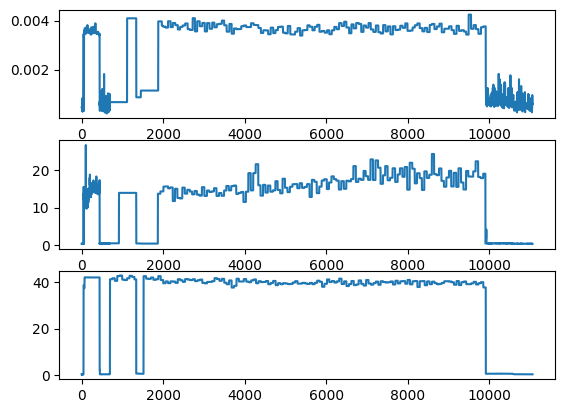

In [5]:
plt.subplot(3, 1, 1)
plt.plot(df_final[df_final['equipment_id']== 'A']['ACR_Pmp.PV'])
plt.subplot(3, 1, 2)
plt.plot(df_final[df_final['equipment_id']== 'A']['ACR_Mot.SV'])
plt.subplot(3, 1, 3)
plt.plot(df_final[df_final['equipment_id']== 'A']['Pres.PV'])